# 04 — The shared instrument: a federated demand forecaster (extended history)

**Goal (PROBLEM.md):** branches jointly learn one demand forecaster **without sharing raw
data** — model weight updates travel, patient-level activity never does. The forecaster is
the instrument the request/allocation loop reads; this notebook is its honesty certificate.

- Per-branch training tables: lags 1/2/3/12, backlog & throughput at t−1, month sin/cos;
  per-series z-score of log1p with **train-only stats** (no leakage).
- Time split by date: train ≤ 2024-09 · val ≤ 2025-03 · **test = final 12 months** —
  same boundaries as the laptop run, so results stay comparable; with 96 months the
  train window simply extends back (targets from 2019-04 where history allows).
- **Frozen panel:** series = those complete on 2021-04..2026-03 (the same 694).
- Model: specialty-embedding MLP (~1.8k params) predicting the **residual on last month**,
  L1 loss (matches the MAE metric). FedAvg written manually — every step inspectable.
- The ladder (identical protocol per rung, val-selected): naive · local-only · FedAvg ·
  FedAvg+fine-tune · centralized. Persists all models for the decision notebooks.

In [1]:
import numpy as np
import pandas as pd

long = pd.read_csv("../data/processed/rtt_long.csv")
key = ["provider_code", "specialty_code", "month"]
ser = ["provider_code", "specialty_code"]
cnt = long.pivot_table(index=key, columns="part", values="total_all", aggfunc="sum").reset_index()
wide = pd.DataFrame({"provider_code": cnt["provider_code"], "specialty_code": cnt["specialty_code"],
                     "month": cnt["month"], "demand": cnt["Part_3"], "backlog": cnt["Part_2"],
                     "throughput": cnt["Part_1A"].fillna(0) + cnt["Part_1B"].fillna(0)})
# FROZEN PANEL (pre-registered): series complete on 2021-04..2026-03; extra months = history only
WINDOW = ("2021-04", "2026-03")
core = wide[wide["month"].between(*WINDOW)]
ok = core.dropna(subset=["demand"]).query("demand > 0").groupby(ser)["month"].nunique()
wide = wide.set_index(ser).loc[ok[ok == core["month"].nunique()].index].reset_index()
wide[["backlog", "throughput"]] = wide[["backlog", "throughput"]].fillna(0)
wide = wide.sort_values(ser + ["month"]).reset_index(drop=True)

g = wide.groupby(ser, sort=False)
f = wide[key].copy()
f["demand"] = wide["demand"]
f["y"] = np.log1p(wide["demand"])
for lag in [1, 2, 3, 12]:
    f[f"lag{lag}"] = g["demand"].shift(lag).pipe(np.log1p)
f["backlog"] = g["backlog"].shift(1).pipe(np.log1p)
f["throughput"] = g["throughput"].shift(1).pipe(np.log1p)
mnum = f["month"].str[5:7].astype(int)
f["month_sin"] = np.sin(2 * np.pi * mnum / 12)
f["month_cos"] = np.cos(2 * np.pi * mnum / 12)
f = f.dropna().reset_index(drop=True)
f = f[f["demand"] > 0].reset_index(drop=True)  # pre-2021 history may hold zero months — not valid targets
f["split"] = np.where(f["month"] <= "2024-09", "train", np.where(f["month"] <= "2025-03", "val", "test"))

tr = f[f["split"] == "train"]
stats = tr.groupby(ser).agg(mu=("y", "mean"), sd=("y", "std"),
                            mu_b=("backlog", "mean"), sd_b=("backlog", "std"),
                            mu_t=("throughput", "mean"), sd_t=("throughput", "std")).reset_index()
stats[["sd", "sd_b", "sd_t"]] = stats[["sd", "sd_b", "sd_t"]].clip(lower=1e-6)
f = f.merge(stats, on=ser)
f["y"] = (f["y"] - f["mu"]) / f["sd"]
for c in ["lag1", "lag2", "lag3", "lag12"]:
    f[c] = (f[c] - f["mu"]) / f["sd"]
f["backlog"] = (f["backlog"] - f["mu_b"]) / f["sd_b"]
f["throughput"] = (f["throughput"] - f["mu_t"]) / f["sd_t"]
f = f.drop(columns=["mu_b", "sd_b", "mu_t", "sd_t"])
f.to_csv("../data/processed/features.csv", index=False)

# leakage + alignment asserts
s = f[(f["provider_code"] == "RAJ") & (f["specialty_code"] == "C_130") &
      (f["month"] >= "2021-04")].sort_values("month")  # frozen window = known contiguous
assert np.allclose(s["lag1"].values[1:], s["y"].values[:-1]), "lag misaligned"
chk = f[f["split"] == "train"].groupby(ser)["y"].agg(["mean", "std"])
assert np.allclose(chk["mean"], 0, atol=1e-6) and np.allclose(chk["std"], 1, atol=1e-3), "stats not train-only"
print(f"features: {len(f)} rows | series {f.groupby(ser).ngroups} | "
      f"train/val/test {(f['split'] == 'train').sum()}/{(f['split'] == 'val').sum()}/{(f['split'] == 'test').sum()}")

features: 33312 rows | series 694 | train/val/test 20820/4164/8328


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

FEATS = ["lag1", "lag2", "lag3", "lag12", "backlog", "throughput", "month_sin", "month_cos"]
specs = sorted(f["specialty_code"].unique())
f["spec"] = f["specialty_code"].map({s: i for i, s in enumerate(specs)})
trusts = sorted(f["provider_code"].unique())
splits = {s: f[f["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
te = splits["test"]
device = "cuda" if torch.cuda.is_available() else "cpu"

def tensors(rows):
    return (torch.tensor(rows[FEATS].values, dtype=torch.float32).to(device),
            torch.tensor(rows["spec"].values).to(device),
            torch.tensor(rows["y"].values, dtype=torch.float32).to(device))

class Net(nn.Module):
    def __init__(self, emb=4, hidden=32):
        super().__init__()
        self.emb = nn.Embedding(len(specs), emb)
        self.mlp = nn.Sequential(nn.Linear(len(FEATS) + emb, hidden), nn.ReLU(),
                                 nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))
    def forward(self, x, s):  # residual on lag1 -> the model STARTS at the naive baseline
        return x[:, 0] + self.mlp(torch.cat([x, self.emb(s)], dim=1)).squeeze(-1)

def train_epochs(model, rows, epochs, lr=1e-3, batch=256):
    x, s, y = tensors(rows)
    dl = DataLoader(TensorDataset(x, s, y), batch_size=batch, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for _ in range(epochs):
        for xb, sb, yb in dl:
            opt.zero_grad()
            nn.functional.l1_loss(model(xb, sb), yb).backward()  # L1 = same shape as MAE metric
            opt.step()
    return model

@torch.no_grad()
def predict_demand(model, rows):
    x, s, _ = tensors(rows)
    model.eval()
    ylog = model(x, s).cpu().numpy() * rows["sd"].values + rows["mu"].values
    return np.expm1(ylog)

def mae(rows, pred):  # (mean per-branch MAE, pooled MAE) in referral units
    err = np.abs(pred - rows["demand"].values)
    return pd.Series(err).groupby(rows["provider_code"].values).mean().mean(), err.mean()

def fit_with_val(rows_tr, rows_va, epochs=40, lr=1e-3, seed=0, init=None):
    torch.manual_seed(seed)
    model = Net().to(device)
    if init is not None:
        model.load_state_dict(init)
    best, best_m = None, np.inf
    for _ in range(epochs):
        train_epochs(model, rows_tr, 1, lr)
        m, _ = mae(rows_va, predict_demand(model, rows_va))
        if m < best_m:
            best_m, best = m, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best)
    return model

print(f"device: {device} | branches: {len(trusts)} | departments: {len(specs)}")

device: cuda | branches: 35 | departments: 23


In [3]:
# rung 0: no-learning baselines · rung 1: every branch alone (the world WITHOUT the federation)
results = {}
for name, col in [("naive (last month)", "lag1"), ("seasonal-naive (t-12)", "lag12")]:
    pred = np.expm1(te[col].values * te["sd"].values + te["mu"].values)
    results[name] = mae(te, pred)

pred = np.zeros(len(te))
local_models = {}
for t in trusts:
    m = fit_with_val(splits["train"][splits["train"]["provider_code"] == t],
                     splits["val"][splits["val"]["provider_code"] == t])
    local_models[t] = {k: v.cpu() for k, v in m.state_dict().items()}
    mask = (te["provider_code"] == t).values
    pred[mask] = predict_demand(m, te[mask])
results["local-only"] = mae(te, pred)
for k, v in results.items():
    print(f"{k}: per-branch MAE {v[0]:.1f} | pooled {v[1]:.1f}")

naive (last month): per-branch MAE 111.2 | pooled 111.7
seasonal-naive (t-12): per-branch MAE 144.9 | pooled 145.7
local-only: per-branch MAE 106.9 | pooled 107.3


In [4]:
# rung 2: FedAvg — weights travel, data does not. rung 3: + fair fine-tune. rung 4: centralized.
def fedavg(rounds=100, local_epochs=2, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    global_model = Net().to(device)
    client_rows = {t: splits["train"][splits["train"]["provider_code"] == t] for t in trusts}
    weights = {t: len(client_rows[t]) / len(splits["train"]) for t in trusts}
    best, best_m, curve = None, np.inf, []
    for r in range(rounds):
        avg = None
        for t in trusts:  # each branch trains from global weights on ITS OWN rows only
            local = Net().to(device)
            local.load_state_dict(global_model.state_dict())
            train_epochs(local, client_rows[t], local_epochs, lr)
            sd = local.state_dict()
            avg = {k: weights[t] * v for k, v in sd.items()} if avg is None \
                  else {k: avg[k] + weights[t] * sd[k] for k in avg}
        global_model.load_state_dict(avg)
        m, _ = mae(splits["val"], predict_demand(global_model, splits["val"]))
        curve.append(m)
        if m < best_m:
            best_m, best = m, {k: v.clone() for k, v in avg.items()}
    global_model.load_state_dict(best)
    return global_model, curve

fed, curve = fedavg()
results["FedAvg"] = mae(te, predict_demand(fed, te))

pred = np.zeros(len(te))
ft_models = {}
for t in trusts:  # identical protocol to local-only; only the init differs (federated weights)
    m = fit_with_val(splits["train"][splits["train"]["provider_code"] == t],
                     splits["val"][splits["val"]["provider_code"] == t], init=fed.state_dict())
    ft_models[t] = {k: v.cpu() for k, v in m.state_dict().items()}
    mask = (te["provider_code"] == t).values
    pred[mask] = predict_demand(m, te[mask])
results["FedAvg + fine-tune"] = mae(te, pred)

central = fit_with_val(splits["train"], splits["val"])
results["centralized (upper bound)"] = mae(te, predict_demand(central, te))
for k in ["FedAvg", "FedAvg + fine-tune", "centralized (upper bound)"]:
    print(f"{k}: per-branch MAE {results[k][0]:.1f} | pooled {results[k][1]:.1f}")

FedAvg: per-branch MAE 110.9 | pooled 111.4
FedAvg + fine-tune: per-branch MAE 108.1 | pooled 108.6
centralized (upper bound): per-branch MAE 114.2 | pooled 114.7


                           per-branch MAE  pooled MAE
local-only                          106.9       107.3
FedAvg + fine-tune                  108.1       108.6
FedAvg                              110.9       111.4
naive (last month)                  111.2       111.7
centralized (upper bound)           114.2       114.7
seasonal-naive (t-12)               144.9       145.7


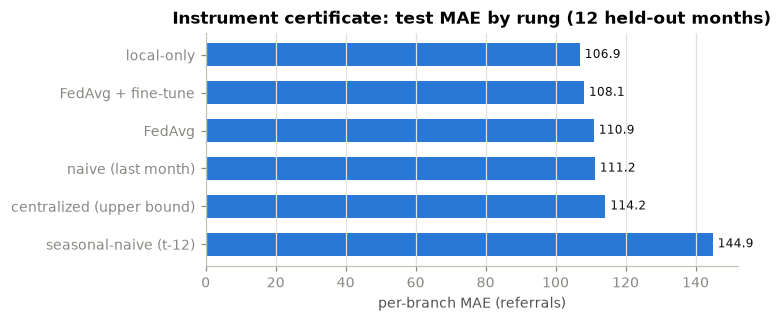

saved models_src.pt (global + 35 fine-tuned + 35 local) and results_src.json


In [5]:
# persist the instrument + its certificate
import json
import matplotlib.pyplot as plt
torch.save({"fed_global": {k: v.cpu() for k, v in fed.state_dict().items()},
            "fed_ft": ft_models, "local": local_models, "specs": specs, "feats": FEATS},
           "../data/processed/models_src.pt")
with open("../data/processed/results_src.json", "w") as out:
    json.dump({k: {"per_branch_mae": v[0], "pooled_mae": v[1]} for k, v in results.items()}, out, indent=2)

table = pd.DataFrame(results, index=["per-branch MAE", "pooled MAE"]).T.round(1).sort_values("per-branch MAE")
print(table.to_string())

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
})
fig, ax = plt.subplots(figsize=(7, 3))
s = table.iloc[::-1]
ax.barh(s.index, s["per-branch MAE"], color="#2a78d6", height=0.6)
for i, v in enumerate(s["per-branch MAE"].values):
    ax.text(v + s["per-branch MAE"].max() * 0.01, i, f"{v:.1f}", va="center", fontsize=8, color="#0b0b0b")
ax.set_title("Instrument certificate: test MAE by rung (12 held-out months)")
ax.set_xlabel("per-branch MAE (referrals)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print("saved models_src.pt (global + 35 fine-tuned + 35 local) and results_src.json")